# 02 · Baseline — TF-IDF + Logistic Regression (categoría)
Split temporal: train ≤ 2026-05, test 2026-06 → 2026-08. Primer vistazo de equidad por `Tags`.

Memoria: se eligen las filas con columnas pequeñas y solo esas narrativas se leen, por lotes.
HashingVectorizer evita el diccionario de bigramas (decenas de millones de entradas).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.pipeline import make_pipeline

from training.cfpb import load_product_map, map_categories, read_narratives

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
(ROOT / "reports").mkdir(exist_ok=True)
DATA = ROOT / "data" / "cfpb" / "complaints.parquet"
SEED = 42

meta = pq.read_table(DATA, columns=["date_received", "product", "tags"]).to_pandas(
    strings_to_categorical=True
)
meta["category"] = map_categories(
    meta["product"].astype(str), load_product_map(ROOT / "datasets" / "categories_v1.json")
)
meta = meta.dropna(subset=["category"])
train_idx = (
    meta[meta["date_received"] < "2026-06-01"].sample(150_000, random_state=SEED).index.to_numpy()
)
test_idx = meta[meta["date_received"] >= "2026-06-01"].index.to_numpy()

train = meta.loc[train_idx].assign(narrative=read_narratives(DATA, train_idx))
test = meta.loc[test_idx].assign(narrative=read_narratives(DATA, test_idx))
del meta
print(f"train={len(train):,} test={len(test):,}")

train=150,000 test=26,823


In [2]:
model = make_pipeline(
    HashingVectorizer(ngram_range=(1, 2), n_features=2**20, alternate_sign=False, norm=None),
    TfidfTransformer(sublinear_tf=True),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
model.fit(train["narrative"], train["category"])
pred = model.predict(test["narrative"])

macro_f1 = f1_score(test["category"], pred, average="macro")
print(f"macro-F1 = {macro_f1:.3f}")
print(classification_report(test["category"], pred, digits=3))

macro-F1 = 0.814
                    precision    recall  f1-score   support

     bank_accounts      0.777     0.819     0.797      5295
             cards      0.818     0.817     0.817      5017
    consumer_loans      0.786     0.799     0.792      2348
  credit_reporting      0.604     0.782     0.681      1452
   debt_collection      0.936     0.867     0.900      7825
          mortgage      0.941     0.932     0.937      1879
payments_transfers      0.690     0.664     0.677      2121
     student_loans      0.948     0.870     0.908       886

          accuracy                          0.826     26823
         macro avg      0.813     0.819     0.814     26823
      weighted avg      0.833     0.826     0.828     26823



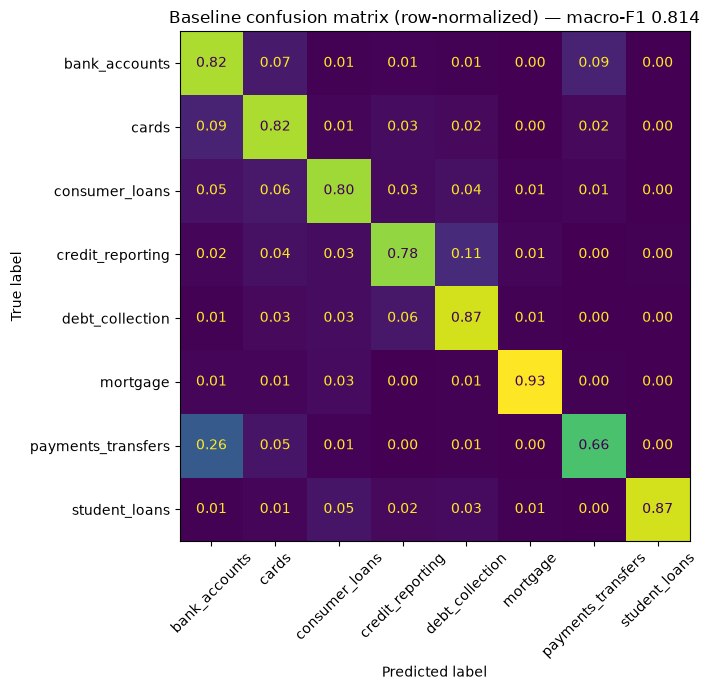

In [3]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test["category"],
    pred,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    ax=ax,
    colorbar=False,
)
ax.set_title(f"Baseline confusion matrix (row-normalized) — macro-F1 {macro_f1:.3f}")
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_confusion_matrix.png", dpi=150)
plt.show()
plt.close(fig)

## Equidad: macro-F1 por grupo

In [4]:
test = test.assign(pred=pred)
tags = test["tags"].astype(str)
groups = {
    "Older American": tags.str.contains("Older American"),
    "Servicemember": tags.str.contains("Servicemember"),
    "No tag": tags == "",
}
rows = []
for name, mask in groups.items():
    sub = test[mask]
    f1 = f1_score(sub["category"], sub["pred"], average="macro")
    rows.append({"group": name, "n": len(sub), "macro_f1": f1})
fairness = pd.DataFrame(rows).round(3)
fairness

,group,n,macro_f1
0,Older American,2034,0.724
1,Servicemember,2844,0.747
2,No tag,22378,0.819


In [5]:
results = {
    "model": "tfidf_logreg_baseline",
    "train_rows": len(train),
    "test_rows": len(test),
    "macro_f1": round(float(macro_f1), 4),
    "accuracy": round(float(np.mean(pred == test["category"])), 4),
    "fairness_macro_f1": fairness.set_index("group")["macro_f1"].to_dict(),
}
(ROOT / "reports" / "baseline_metrics.json").write_text(json.dumps(results, indent=2) + "\n")
print(json.dumps(results, indent=2))

{
  "model": "tfidf_logreg_baseline",
  "train_rows": 150000,
  "test_rows": 26823,
  "macro_f1": 0.8137,
  "accuracy": 0.8262,
  "fairness_macro_f1": {
    "Older American": 0.724,
    "Servicemember": 0.747,
    "No tag": 0.819
  }
}
